# Project B: 2D Radiation Transport in Tissue

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from dataclasses import dataclass

### Geometry

The overall rectangle is made up of water

Within the water rectangle are two smaller rectangles of one air pocket and one bone piece

In [137]:
# Overall water rectangle
water_rect = {
    'start_x' : 0,
    'start_y': 0,
    'length': 200,
    'height': 300,
    'label': 'Water',
    'color': 'lightblue',
    'fill': True,
}

air_rect = {
    'start_x' : 62.5,
    'start_y': 165,
    'length': 75,
    'height': 75,
    'label': 'Air',
    'color': 'gainsboro',
    'fill': True
}

bone_rect = {
    'start_x' : 62.5,
    'start_y': 65,
    'length': 75,
    'height': 75,
    'label': 'Bone',
    'color': 'grey',
    'fill': True
}

rects = [water_rect, air_rect, bone_rect]

### Single object test

$\mu = \rho(\frac{\mu}{\rho_{H2O}})$. For a photon of 1 MeV, $\frac{\mu}{\rho}=7.702e-2$ cm^2/g, and $\rho=1$ g/cm^3. We sample the distance traveled from an inverse exponential distribution, $$s=-\frac{ln(u)}{\mu}$$

In [226]:
xray_energy = 1
mu_p_h20 = 7.072e-2
p = 1
mu_water = mu_p_h20 * 1 #cm^-1
average_travelled = 1/mu_water

# randomly choose a depth number s.t distribution gives an exponential decay
# so I sample the linear attenuation of 

# inverse transform sampling equation for an exponential distribution
nphotons = 10000
u = np.random.rand(nphotons)
s = -np.log(u)/mu_water
average_sampled = np.mean(s)

print(f"Average analytic traveled: {average_travelled:0.5f}")
print(f"Average sample traveled: {average_sampled:0.5f}")

# entering height of the photon
y = np.random.randint(0,300,nphotons)

Average analytic traveled: 14.14027
Average sample traveled: 14.03658


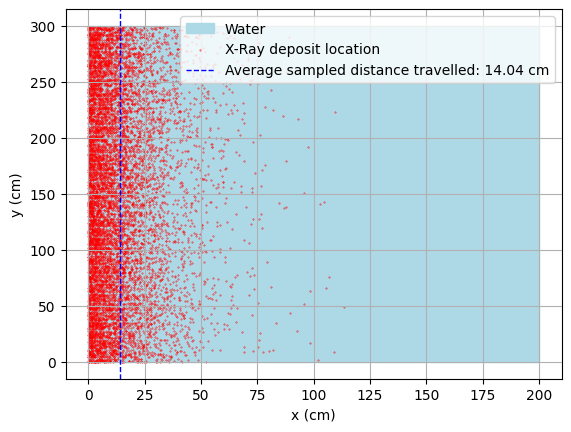

In [227]:
fig, ax = plt.subplots()


start_x = water_rect['start_x']
start_y = water_rect['start_y']
length = water_rect['length']
height = water_rect['height']
label_legend = water_rect['label']
color = water_rect['color']
fill_bool = water_rect['fill']

ax.add_patch(Rectangle((start_x, start_y), length, height, label = label_legend, fill = fill_bool, color=color))
ax.scatter(s,y, s=0.1, color = "red", label = "X-Ray deposit location")
ax.axvline(average_sampled, color='blue', linestyle='--', linewidth=1, label=f'Average sampled distance travelled: {np.mean(s):0.2f} cm')

ax.grid(True)
ax.set_xlabel("x (cm)")
ax.set_ylabel("y (cm)")
plt.legend()
plt.show()

### Fitting attenuation functions

#### Water - Photon

https://physics.nist.gov/PhysRefData/XrayMassCoef/ComTab/water.html

In [316]:
water_photon_energy = np.array([
    1.00000e-03, 1.50000e-03, 2.00000e-03, 3.00000e-03,
    4.00000e-03, 5.00000e-03, 6.00000e-03, 8.00000e-03,
    1.00000e-02, 1.50000e-02, 2.00000e-02, 3.00000e-02,
    4.00000e-02, 5.00000e-02, 6.00000e-02, 8.00000e-02,
    1.00000e-01, 1.50000e-01, 2.00000e-01, 3.00000e-01,
    4.00000e-01, 5.00000e-01, 6.00000e-01, 8.00000e-01,
    1.00000e+00, 1.25000e+00, 1.50000e+00, 2.00000e+00,
    3.00000e+00, 4.00000e+00, 5.00000e+00, 6.00000e+00,
    8.00000e+00, 1.00000e+01, 1.50000e+01, 2.00000e+01
])

mass_attenuation_water_photon = np.array([
    4.078e+03, 1.376e+03, 6.173e+02, 1.929e+02,
    8.278e+01, 4.258e+01, 2.464e+01, 1.037e+01,
    5.329e+00, 1.673e+00, 8.096e-01, 3.756e-01,
    2.683e-01, 2.269e-01, 2.059e-01, 1.837e-01,
    1.707e-01, 1.505e-01, 1.370e-01, 1.186e-01,
    1.061e-01, 9.687e-02, 8.956e-02, 7.865e-02,
    7.072e-02, 6.323e-02, 5.754e-02, 4.942e-02,
    3.969e-02, 3.403e-02, 3.031e-02, 2.770e-02,
    2.429e-02, 2.219e-02, 1.941e-02, 1.813e-02
])

In [317]:
log_energy = np.log10(water_photon_energy)
log_attenuation = np.log10(mass_attenuation_water_photon)

photon_water_coefficients = np.polyfit(log_energy, log_attenuation, deg=50)

/var/folders/y6/_vtfk1x97_g2hvv8pf8qkfgr0000gn/T/ipykernel_5307/1347875007.py:4: RankWarning: Polyfit may be poorly conditioned
  photon_water_coefficients = np.polyfit(log_energy, log_attenuation, deg=50)


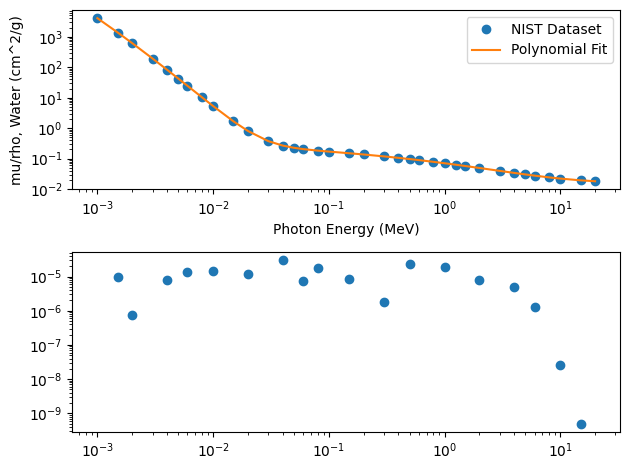

In [318]:
def water_photon_attenuation(energy):
    attenuation = 10 ** np.polyval(photon_water_coefficients, np.log10(energy))
    return attenuation

water_photon_attenuation_fit = water_photon_attenuation(water_photon_energy)
residuals = mass_attenuation_water_photon - water_photon_attenuation_fit

fig, ax = plt.subplots(2,1)

ax[0].plot(water_photon_energy, mass_attenuation_water_photon, "o", label="NIST Dataset")
ax[0].plot(water_photon_energy, water_photon_attenuation_fit, label="Polynomial Fit")
ax[0].set_xlabel("Photon Energy (MeV)")
ax[0].set_ylabel("mu/rho, Water (cm^2/g)")
ax[0].set_xscale("log")
ax[0].set_yscale("log")
ax[0].legend()

ax[1].scatter(water_photon_energy, residuals)
ax[1].set_xscale("log")
ax[1].set_yscale("log")

fig.tight_layout()

#### Bone - Photon
https://physics.nist.gov/PhysRefData/XrayMassCoef/ComTab/bone.html

In [319]:
bone_photon_energy = np.array([
    1.00000e-03, 1.03542e-03, 1.07210e-03, 1.07210e-03,
    1.18283e-03, 1.30500e-03, 1.30500e-03, 1.50000e-03,
    2.00000e-03, 2.14550e-03, 2.14550e-03, 2.30297e-03,
    2.47200e-03, 2.47200e-03, 3.00000e-03, 4.00000e-03,
    4.03810e-03, 4.03810e-03, 5.00000e-03, 6.00000e-03,
    8.00000e-03, 1.00000e-02, 1.50000e-02, 2.00000e-02,
    3.00000e-02, 4.00000e-02, 5.00000e-02, 6.00000e-02,
    8.00000e-02, 1.00000e-01, 1.50000e-01, 2.00000e-01,
    3.00000e-01, 4.00000e-01, 5.00000e-01, 6.00000e-01,
    8.00000e-01, 1.00000e+00, 1.25000e+00, 1.50000e+00,
    2.00000e+00, 3.00000e+00, 4.00000e+00, 5.00000e+00,
    6.00000e+00, 8.00000e+00, 1.00000e+01, 1.50000e+01,
    2.00000e+01
])

bone_mass_attenuation_photon = np.array([
    3.781e+03, 3.452e+03, 3.150e+03, 3.156e+03,
    2.434e+03, 1.873e+03, 1.883e+03, 1.295e+03,
    5.869e+02, 4.824e+02, 7.114e+02, 5.916e+02,
    4.907e+02, 4.962e+02, 2.958e+02, 1.331e+02,
    1.296e+02, 3.332e+02, 1.917e+02, 1.171e+02,
    5.323e+01, 2.851e+01, 9.032e+00, 4.001e+00,
    1.331e+00, 6.655e-01, 4.242e-01, 3.148e-01,
    2.229e-01, 1.855e-01, 1.480e-01, 1.309e-01,
    1.113e-01, 9.908e-02, 9.022e-02, 8.332e-02,
    7.308e-02, 6.566e-02, 5.871e-02, 5.346e-02,
    4.607e-02, 3.745e-02, 3.257e-02, 2.946e-02,
    2.734e-02, 2.467e-02, 2.314e-02, 2.132e-02,
    2.068e-02
])

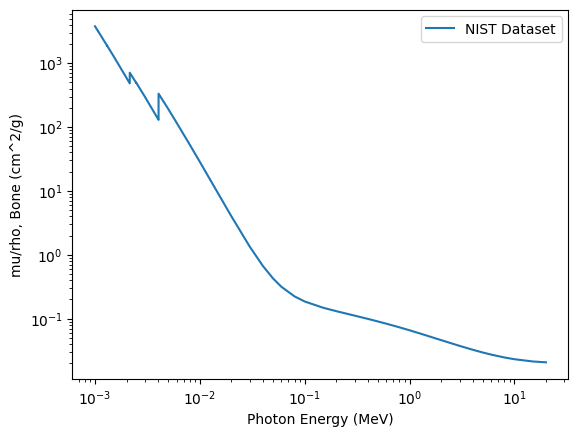

In [323]:
plt.plot(bone_photon_energy, bone_mass_attenuation_photon, label="NIST Dataset")
plt.xlabel("Photon Energy (MeV)")
plt.ylabel("mu/rho, Bone (cm^2/g)")
plt.xscale("log")
plt.yscale("log")
plt.legend()

In [ ]:
log_energy = np.log10(bone_photon_energy)
log_attenuation = np.log10(bone_mass_attenuation_photon)

photon_bone_coefficients = np.polyfit(log_energy, log_attenuation, deg=100)

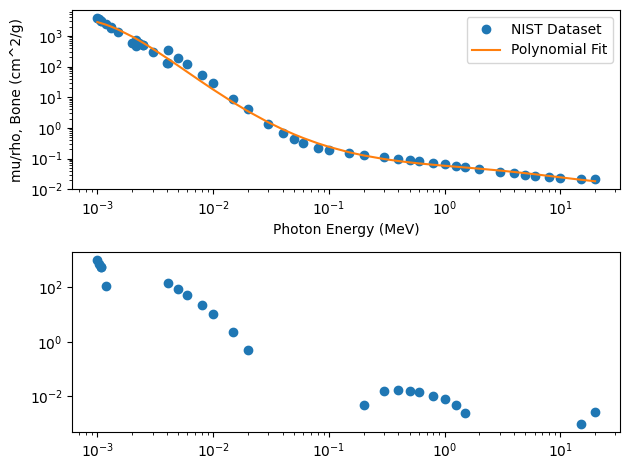

In [325]:
def bone_photon_attenuation(energy):
    attenuation = 10 ** np.polyval(photon_bone_coefficients, np.log10(energy))
    return attenuation

bone_photon_attenuation_fit = bone_photon_attenuation(bone_photon_energy)
residuals = bone_mass_attenuation_photon - bone_photon_attenuation_fit

fig, ax = plt.subplots(2,1)

ax[0].plot(bone_photon_energy, bone_mass_attenuation_photon, "o", label="NIST Dataset")
ax[0].plot(bone_photon_energy,bone_photon_attenuation_fit, label="Polynomial Fit")
ax[0].set_xlabel("Photon Energy (MeV)")
ax[0].set_ylabel("mu/rho, Bone (cm^2/g)")
ax[0].set_xscale("log")
ax[0].set_yscale("log")
ax[0].legend()

ax[1].scatter(bone_photon_energy, residuals)
ax[1].set_xscale("log")
ax[1].set_yscale("log")

fig.tight_layout()

### Particle Class

In [ ]:
@dataclass
class Particle:
    ptype: str
    pos: np.ndarray # (2,)
    dir: np.ndarray # (2,)
    energy: float   # MeV
    active: bool    # Deposited or not

### Adding bone and air

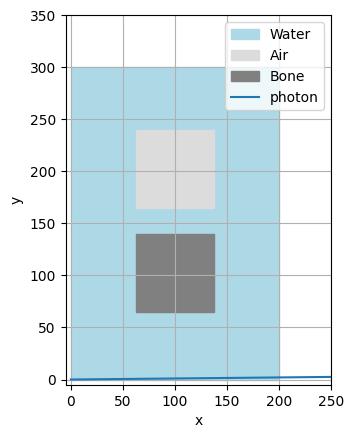

In [228]:
fig, ax = plt.subplots()

for rectangle in rects:
    start_x = rectangle['start_x']
    start_y = rectangle['start_y']
    length = rectangle['length']
    height = rectangle['height']
    label_legend = rectangle['label']
    color = rectangle['color']
    fill_bool = rectangle['fill']
    ax.add_patch(Rectangle((start_x, start_y), length, height, label = label_legend, fill = fill_bool, color=color))


photon1 = np.array([0, 0, 150, 0])
time_array = np.linspace(0,100,1000)
x = 0.1*time_array
plt.plot(x, label = "photon")


ax.set_aspect("equal")
ax.set_xlim(-5, 250)
ax.set_ylim(-5, 350)
ax.grid(True)
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.legend()
plt.show()